# SLA diagnostics and operational investigation
Rates are associations; seller diagnostics use single-seller orders. Wilson intervals show uncertainty.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
def report(name): return pd.read_csv(ROOT / 'reports' / (name + '.csv'))
def metadata(name): return json.loads((ROOT / 'reports' / (name + '.json')).read_text())
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
metadata('kpis')

{'total_orders': 99441,
 'eligible_orders': 96470,
 'excluded_orders': 2971,
 'late_orders': 6534,
 'late_rate': 0.06773090079817559,
 'on_time_rate': 0.9322690992018244,
 'average_delivery_days': 12.558217098051976,
 'p90_delivery_days': 23.09637731481482,
 'average_delay_days': 0.7193117031201409,
 'item_value': 13591643.7,
 'freight_value': 2251909.54,
 'payment_value': 16008872.120000001,
 'reviewed_orders': 98673,
 'dissatisfaction_rate': 0.1468892199487195,
 'purchase_min': '2016-09-04 21:15:19',
 'purchase_max': '2018-10-17 17:30:18'}

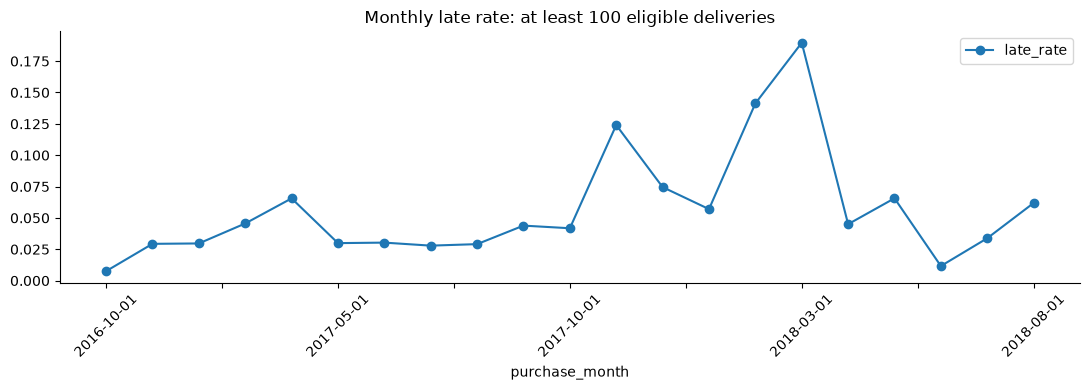

In [3]:
monthly=report('agg_monthly')
monthly.query('eligible_orders>=100').plot(x='purchase_month',y='late_rate',marker='o',title='Monthly late rate: at least 100 eligible deliveries'); plt.xticks(rotation=45);plt.tight_layout();plt.show()

In [4]:
regions=report('agg_region').query('eligible_orders>=500').sort_values('late_rate',ascending=False)
regions[['customer_state','eligible_orders','late_rate','late_rate_ci_low','late_rate_ci_high','p90_delivery_days']]

,customer_state,eligible_orders,late_rate,late_rate_ci_low,late_rate_ci_high,p90_delivery_days
9,MA,717,0.174338,0.148322,0.203824,34.315898
5,CE,1279,0.137608,0.119810,0.157575,34.719032
4,BA,3256,0.121622,0.110838,0.133297,31.812529
18,RJ,12350,0.121053,0.115417,0.126924,29.086966
13,PA,946,0.112051,0.093498,0.133741,39.234780
7,ES,1995,0.107268,0.094436,0.121610,25.349815
14,PB,517,0.104449,0.080938,0.133794,34.950354
11,MS,701,0.097004,0.077241,0.121161,24.653426
15,PE,1593,0.096045,0.082532,0.111502,30.911639
23,SC,3546,0.082064,0.073476,0.091557,25.793501


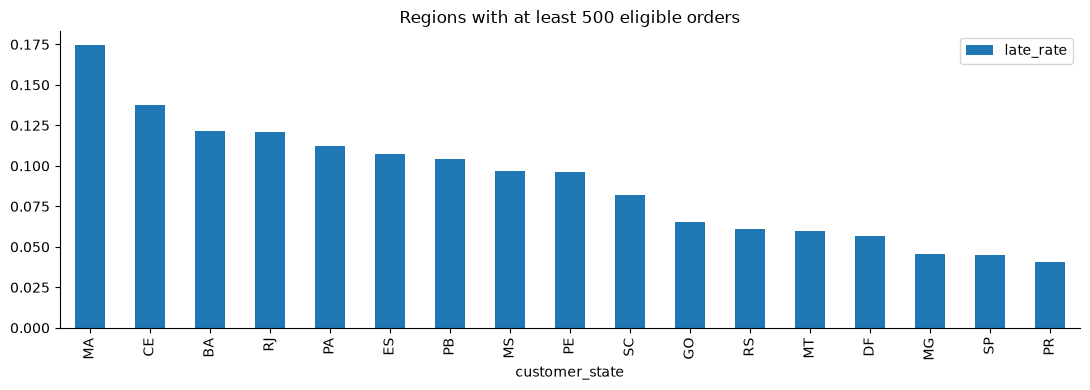

In [5]:
regions.plot.bar(x='customer_state',y='late_rate',title='Regions with at least 500 eligible orders');plt.tight_layout();plt.show()

In [6]:
report('agg_seller').query('eligible_orders>=50').sort_values('late_rate',ascending=False).head(15)

,seller_id,eligible_orders,late_orders,late_rate,avg_delivery_days,late_rate_ci_low,late_rate_ci_high
1024,54965bbe3e4f07ae045b90b0b8541f52,72,22.0,0.305556,26.362038,0.211265,0.419545
2286,beadbee30901a7f61d031b6b686095ad,63,15.0,0.238095,14.129265,0.149937,0.356359
1993,a49928bcdf77c55c6d6e05e09a9b4ca5,93,21.0,0.225806,17.038833,0.152700,0.320666
1379,712e6ed8aa4aa1fa65dab41fed5737e4,77,16.0,0.207792,24.691599,0.132150,0.311206
2532,d20b021d3efdf267a402c402a48ea64b,73,14.0,0.191781,18.082351,0.117823,0.296557
80,06a2c3af7b3aee5d69171b0e14f0ee87,388,74.0,0.190722,17.769048,0.154736,0.232772
1660,88460e8ebdecbfecb5f9601833981930,227,42.0,0.185022,18.175388,0.139897,0.240631
2815,ea566164622c6b439516ab18062c42cd,50,9.0,0.180000,14.027645,0.097701,0.307963
1172,6039e27294dc75811c0d8a39069f52c0,62,11.0,0.177419,18.170806,0.102063,0.290418
2444,cac4c8e7b1ca6252d8f20b2fc1a2e4af,69,12.0,0.173913,18.700125,0.102383,0.279838


In [7]:
report('customer_experience')

,is_late,reviewed,dissatisfied,average_score,dissatisfaction_rate
0,0.0,89443,8289,4.290386,0.092674
1,1.0,6381,3983,2.270491,0.624197


In [8]:
report('fulfillment_stages')

,handoff_after_item_deadline,orders,late_rate,avg_handoff_days,avg_transit_days
0,0.0,79128,0.055657,2.567624,9.389553
1,1.0,7706,0.210096,9.669080,9.967496


In [9]:
report('region_category_strata').query('eligible>=100').sort_values('late_rate',ascending=False).head(20)

,customer_state,primary_category,eligible,late_rate
136,BA,auto,145,0.179310
972,RJ,electronics,391,0.171355
227,CE,health_beauty,152,0.171053
952,RJ,baby,330,0.160606
167,BA,furniture_decor,194,0.159794
963,RJ,construction_tools_construction,101,0.158416
192,BA,telephony,218,0.155963
319,ES,bed_bath_table,196,0.153061
953,RJ,bed_bath_table,1341,0.150634
353,ES,housewares,101,0.148515


Compare state patterns within primary-category strata before proposing a regional intervention. Handoff/transit comparisons are retrospective diagnostics, excluded from prediction features. No observed association establishes a cause.